In [1]:
# Import the libraries we need
import os
import re
import html
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
objc[5465]: Class AVFFrameReceiver is implemented in both /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/av/.dylibs/libavdevice.61.3.100.dylib (0x13b8c03a8) and /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x17f59c3a8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[5465]: Class AVFAudioReceiver is implemented in both /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/av/.dylibs/libavdevice.61.3.100.dylib (0x13b8c03f8) and /Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-package

In [2]:
# Print the package versions used in this run (for reproducibility)
import sys, sklearn, numpy as np_check
print("python: ", sys.version.split()[0])
print("pandas: ", pd.__version__)
print("numpy: ", np_check.__version__)
print("scikit-learn: ", sklearn.__version__)

import sentence_transformers
print("sentence-transformers: ", sentence_transformers.__version__)

python:  3.12.4
pandas:  3.0.5
numpy:  2.5.3
scikit-learn:  1.9.1
sentence-transformers:  5.1.1


In [3]:
# Folders and settings (paths are relative to the notebooks folder)
DATA_DIR= "../data"
MODEL_DIR= "../models"
os.makedirs(MODEL_DIR, exist_ok= True)

LABELS= {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
LABEL_NAMES= ["World", "Sports", "Business", "Sci/Tech"]
EMB_MODEL= "all-MiniLM-L6-v2" # small sentence embedding model
SEED= 42

In [4]:
# Clean a headline: fix html symbols and remove the news source at the end, like (Reuters)
def clean_text(text):
    text= re.sub(r"\s?#39;", "'", str(text)).replace("quot;", '"')
    text= html.unescape(text)
    text= re.sub(r"<[^>]+>", " ", text) # remove html tags
    text= text.replace("\\", " ")
    text= re.sub(r"\s*\([^)]*\)\s*$", "", text) # remove (Reuters), (AFP), ...
    text= re.sub(r"\s+", " ", text)
    return text.strip()

print(clean_text("Wall St. Bears Claw Back Into the Black (Reuters)"))

Wall St. Bears Claw Back Into the Black


In [5]:
# Load the AG News data. We use the headline (title) only, not the description
# If the csv files are not in the data folder, download them first
URL= "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/"
os.makedirs(DATA_DIR, exist_ok= True)
for name in ["train", "test"]:
    path= f"{DATA_DIR}/{name}.csv"
    if not os.path.exists(path):
        print("downloading", name + ".csv ...")
        pd.read_csv(URL + name + ".csv", header= None).to_csv(path, index= False, header= False)

columns= ["label_id", "title", "description"]
train_df= pd.read_csv(f"{DATA_DIR}/train.csv", header= None, names= columns)
test_df= pd.read_csv(f"{DATA_DIR}/test.csv", header= None, names= columns)

for df in [train_df, test_df]:
    df["text"]= df["title"].apply(clean_text)
    df["label"]= df["label_id"].map(LABELS)

train_df= train_df[["text", "label"]]
test_df= test_df[["text", "label"]]

# Remove empty and duplicate headlines from the training data
train_df= train_df[train_df["text"].str.len() > 0].drop_duplicates()

print("train:", train_df.shape, " test:", test_df.shape)
train_df.head()

train: (111447, 2)  test: (7600, 2)


,text,label
0,Wall St. Bears Claw Back Into the Black,Business
1,Carlyle Looks Toward Commercial Aerospace,Business
2,Oil and Economy Cloud Stocks' Outlook,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,Business
4,"Oil prices soar to all-time record, posing new...",Business


In [6]:
# Split the training data: 90% train, 10% dev (dev is used to choose the best settings)
train, dev = train_test_split(train_df, test_size= 0.1, stratify= train_df["label"], random_state= SEED)
print("train:", len(train), " dev:", len(dev), " test:", len(test_df))
train["label"].value_counts()

train: 100302  dev: 11145  test: 7600


label
Sports      25995
World       25381
Business    24819
Sci/Tech    24107
Name: count, dtype: int64

In [7]:
# Load the embedding model (it turns each headline into a vector of 384 numbers)
encoder= SentenceTransformer(EMB_MODEL)

# Encode the headlines. The vectors are saved in the data folder, so next time we just load them
def get_embeddings(df, name):
    path= f"{DATA_DIR}/emb_{name}.npy"
    if os.path.exists(path):
        emb= np.load(path)
        if len(emb) == len(df):
            return emb
    emb= encoder.encode(df["text"].tolist(), batch_size= 128, show_progress_bar= True, normalize_embeddings= True)
    np.save(path, emb)
    return emb

X_train= get_embeddings(train, "train")
X_dev= get_embeddings(dev, "dev")
X_test= get_embeddings(test_df, "test")
print(f"train: {X_train.shape} - dev: {X_dev.shape} - test: {X_test.shape}")

train: (100302, 384) - dev: (11145, 384) - test: (7600, 384)


In [8]:
# Training: a small neural network (MLP) on top of the embeddings
# It works better than Logistic Regression here because it can learn non-linear patterns
# early_stopping keeps 10% of the train data to stop training before overfitting
best_f1= 0
best_model= None

for size in [256, 512, 1024]:
    model= MLPClassifier(hidden_layer_sizes= (size,), early_stopping= True, max_iter= 50, random_state= SEED)
    model.fit(X_train, train["label"])

    pred= model.predict(X_dev)
    acc= accuracy_score(dev["label"], pred)
    f1= f1_score(dev["label"], pred, average= "macro")
    print(f"Hidden Size= {size}  ->  Model Accuracy= {acc:.4f} - F1-Score= {f1:.4f}")

    if f1 > best_f1:
        best_f1= f1
        best_model= model
        best_size= size

print(f"\nBest Hidden Size: {best_size} - Dev F1-Score: {round(best_f1, 4)}")

Hidden Size= 256  ->  Model Accuracy= 0.8514 - F1-Score= 0.8506
Hidden Size= 512  ->  Model Accuracy= 0.8541 - F1-Score= 0.8531
Hidden Size= 1024  ->  Model Accuracy= 0.8551 - F1-Score= 0.8544

Best Hidden Size: 1024 - Dev F1-Score: 0.8544


In [9]:
# Save the best model in the models folder
joblib.dump(best_model, f"{MODEL_DIR}/emb_mlp.joblib")
print("model saved")

model saved


In [10]:
# Testing: evaluate the best model on the test set (used only once, at the end)
y_test= test_df["label"]
y_pred= best_model.predict(X_test)

print(f"Accuracy: {round(accuracy_score(y_test, y_pred), 4)}")
print(f"Macro F1: {round(f1_score(y_test, y_pred, average= "macro"), 4)}",)
print()
print(classification_report(y_test, y_pred, labels= LABEL_NAMES, digits= 4))

Accuracy: 0.8639
Macro F1: 0.864

              precision    recall  f1-score   support

       World     0.9063    0.8553    0.8800      1900
      Sports     0.9028    0.9242    0.9134      1900
    Business     0.8203    0.8147    0.8175      1900
    Sci/Tech     0.8289    0.8616    0.8449      1900

    accuracy                         0.8639      7600
   macro avg     0.8646    0.8639    0.8640      7600
weighted avg     0.8646    0.8639    0.8640      7600



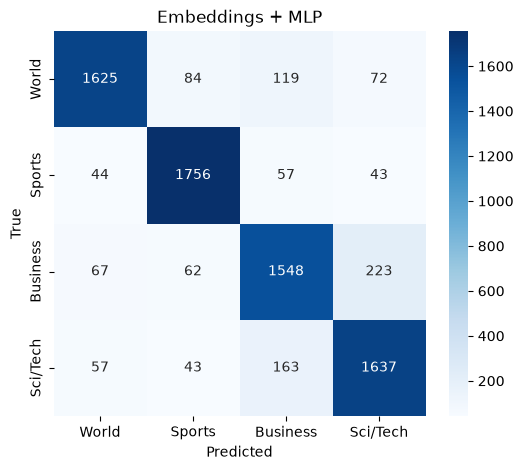

In [11]:
# Confusion matrix: rows are the true topic, columns are the predicted topic
cm= confusion_matrix(y_test, y_pred, labels= LABEL_NAMES)

plt.figure(figsize= (6, 5))
sns.heatmap(cm, annot= True, fmt= "d", cmap= "Blues", xticklabels= LABEL_NAMES, yticklabels= LABEL_NAMES)
plt.title("Embeddings + MLP")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [12]:
# Error analysis: Business and World are the topics the model mixes up the most
results= test_df.copy()
results["pred"]= y_pred

print("Business -> World:", ((results["label"] == "Business") & (results["pred"] == "World")).sum())
print("World -> Business:", ((results["label"] == "World") & (results["pred"] == "Business")).sum())

mistakes= results[(results["label"] != results["pred"]) & results["label"].isin(["Business", "World"])]
mistakes.head(10)

Business -> World: 67
World -> Business: 119


,text,label,pred
33,"Man Sought #36;50M From McGreevey, Aides Say",World,Business
37,1994 Law Designed to Preserve Guard Jobs,World,Business
42,Politics an Afterthought Amid Hurricane,World,Sci/Tech
56,India's Tata expands regional footprint via Na...,World,Business
69,"Suspect charged in abduction, sexual assault o...",World,Sports
79,Live: Olympics day four,World,Sports
83,Intel to delay product aimed for high-definiti...,Business,Sci/Tech
88,U.S. Misses Cut in Olympic 100 Free,World,Sports
104,Mr Downer shoots his mouth off,World,Sports
110,Yahoo! Ups Ante for Small Businesses,Business,Sci/Tech


In [13]:
# Accuracy by headline length (number of words)
results["words"]= results["text"].str.split().str.len()
results["length"]= pd.cut(results["words"], bins= [0, 5, 8, 100], labels= ["<=5", "6-8", ">8"])
results["correct"]= results["label"] == results["pred"]
results.groupby("length", observed= True)["correct"].agg(["count", "mean"]).round(4)

,count,mean
length,,
<=5,2377,0.8368
6-8,4079,0.8713
>8,1144,0.8942


In [14]:
# Try It: load the saved classifier from the models folder (no retraining) and classify a new headline
tryit_model= joblib.load(f"{MODEL_DIR}/emb_mlp.joblib")

def try_it(headline):
    if not headline or not headline.strip():
        print("Please type a news headline first (the input is empty).")
        return
    emb= encoder.encode([clean_text(headline)], normalize_embeddings= True)
    probs= tryit_model.predict_proba(emb)[0]
    best= probs.argmax()
    print(f"Headline : {headline}")
    print(f"Predicted: {tryit_model.classes_[best]} ({probs[best] * 100:.1f}% confidence)")
    print()

try_it("Saudi Aramco reports higher quarterly profit as oil demand grows")
try_it("Al Hilal win the league after a late goal against Al Nassr")
try_it("") # blank input

Headline : Saudi Aramco reports higher quarterly profit as oil demand grows
Predicted: Business (98.8% confidence)

Headline : Al Hilal win the league after a late goal against Al Nassr
Predicted: Sports (88.1% confidence)

Please type a news headline first (the input is empty).
